# Baseline: can a linear model find splice sites?

**Goal.** Before touching a neural network, we want to build the simplest, most sensible models with
`scikit-learn` and see how well they perform. Everything here is at the level of the
Jean Golding Institute course
[Introduction to Data Analysis in Python (Part 2)](https://bristol-training.github.io/data-analysis-python-2/):
load data -> encode features -> train/test split -> fit -> evaluate -> tune a hyperparameter.

**The data.** The UCI *Splice-junction Gene Sequences* set: 3,190 windows of 60 DNA bases
taken from primate genes. Each window is centred on a candidate splice junction and labelled

| label | meaning |
|---|---|
| `EI` | exon -> intron boundary (a *donor* site) |
| `IE` | intron -> exon boundary (an *acceptor* site) |
| `N`  | neither - a random window with no junction |

We should *hopefully* know what to expect, because almost every intron starts with **GT** and ends with
**AG**. If a model is actually learning, then it should, in theory, identify this pattern.

In [6]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from splice_utils import load_splice, one_hot, feature_names, POSITIONS, BASES

df = load_splice("../data/splice.data")
print(df.shape)
print(df["label"].value_counts())
df.head()

(3190, 3)
label
N     1655
IE     768
EI     767
Name: count, dtype: int64


,label,name,sequence
0,EI,ATRINS-DONOR-521,CCAGCTGCATCACAGGAGGCCAGCGAGCAGGTCTGTTCCAAGGGCC...
1,EI,ATRINS-DONOR-905,AGACCCGCCGGGAGGCGGAGGACCTGCAGGGTGAGCCCCACCGCCC...
2,EI,BABAPOE-DONOR-30,GAGGTGAAGGACGTCCTTCCCCAGGAGCCGGTGAGAAGCGCAGTCG...
3,EI,BABAPOE-DONOR-867,GGGCTGCGTTGCTGGTCACATTCCTGGCAGGTATGGGGCGGGGCTT...
4,EI,BABAPOE-DONOR-2817,GCTCAGCCCCCAGGTCACCCAGGAACTGACGTGAGTGTCCCCATCC...


## 1. Turning letters into numbers

A model can't take the string `CCAGCT...` directly. The standard way to get around this is **one-hot encoding**, where
each of the 60 positions becomes four columns (A, C, G, T), with a 1 in the column for the base
that is actually there and 0 elsewhere (binary coded). So one sequence becomes a vector of 60 × 4 = 240 numbers.

A handful of positions (60 out of 191,400) use IUPAC ambiguity codes, where `D` means "A, G or T",
`N` means "any base", and so on. Instead of discarding that data, we can spread the 1 evenly across
the possible bases (a `D` becomes ⅓, ⅓, ⅓ on A, G, T). Below is an example of such.

In [7]:
demo = one_hot(["ACGTD"])          # 5 letters → 20 numbers
pd.DataFrame(demo.reshape(5, 4), index=list("ACGTD"), columns=BASES)

,A,C,G,T
A,1.000000,0.0,0.000000,0.000000
C,0.000000,1.0,0.000000,0.000000
G,0.000000,0.0,1.000000,0.000000
T,0.000000,0.0,0.000000,1.000000
D,0.333333,0.0,0.333333,0.333333


In [8]:
X = one_hot(df["sequence"])
y = df["label"].values
names = feature_names()

print("X shape:", X.shape)        # (3190, 240)
print("first few feature names:", names[:6], "...", names[116:124])

X shape: (3190, 240)
first few feature names: ['-30:A', '-30:C', '-30:G', '-30:T', '-29:A', '-29:C'] ... ['-1:A', '-1:C', '-1:G', '-1:T', '+1:A', '+1:C', '+1:G', '+1:T']


## 2. Hold back a test set

The whole point of a test set is that the model never sees it during training.
`stratify=y` keeps the EI/IE/N proportions the same in both halves.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(len(X_train), "training sequences,", len(X_test), "test sequences")

2392 training sequences, 798 test sequences


## 3. Logistic regression

Logistic regression is the natural first classifier for one-hot features: it learns one weight per
(position, base) pair and adds them up. Keep this model in mind, as in notebook 02 we'll see that a
single artificial neuron holds the same principles.

Logistic regression test accuracy: 0.939

              precision    recall  f1-score   support

          EI       0.90      0.93      0.92       192
          IE       0.91      0.92      0.91       192
           N       0.97      0.95      0.96       414

    accuracy                           0.94       798
   macro avg       0.93      0.93      0.93       798
weighted avg       0.94      0.94      0.94       798



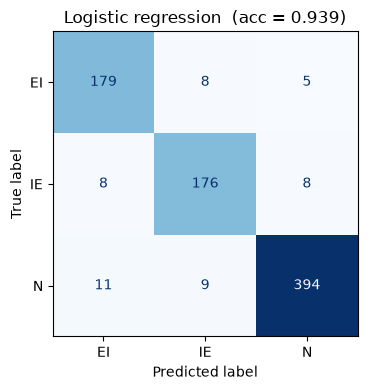

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

logreg = LogisticRegression(max_iter=2000)
logreg.fit(X_train, y_train)

pred = logreg.predict(X_test)
acc_logreg = accuracy_score(y_test, pred)
print(f"Logistic regression test accuracy: {acc_logreg:.3f}\n")
print(classification_report(y_test, pred))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"Logistic regression  (acc = {acc_logreg:.3f})")
plt.tight_layout()
plt.savefig("../figures/01_confusion_logreg.png", dpi=150)
plt.show()

## 4. k-nearest neighbours, and choosing *k*

kNN classifies a sequence by looking at the *k* most similar training sequences. The number *k*
is a **hyperparameter**, meaning it isn't learnt from the data, but we actually specify it. The course's
recipe is `GridSearchCV`: try several values, score each by cross-validation on the training set
only, pick the best, and only then are you permitted to look at the test set.

best k = 31,  kNN test accuracy: 0.857


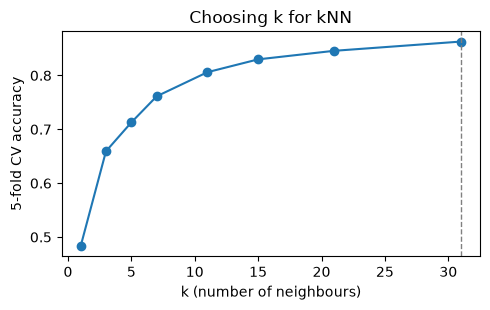

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {"n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]}
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5)
grid.fit(X_train, y_train)

cv_scores = grid.cv_results_["mean_test_score"]
best_k = grid.best_params_["n_neighbors"]
acc_knn = grid.score(X_test, y_test)
print(f"best k = {best_k},  kNN test accuracy: {acc_knn:.3f}")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(param_grid["n_neighbors"], cv_scores, marker="o")
ax.axvline(best_k, color="grey", ls="--", lw=1)
ax.set(xlabel="k (number of neighbours)", ylabel="5-fold CV accuracy", title="Choosing k for kNN")
plt.tight_layout()
plt.savefig("../figures/01_knn_choose_k.png", dpi=150)
plt.show()

## 5. Checking the data, from the perspective of biology

Accuracy is important, but we also want to check if it actually learnt the ***right*** thing. Logistic regression gives one coefficient
per (position, base) for each class, so we can lay them out as a 4 × 60 heatmap. A positive
weight indicates "this base at this position makes the class more likely".

If the model has learned the actual biological rulesets, then we would expect:

* **EI (donor):** strong positive weights for **G at +1** and **T at +2** - the start of the intron.
* **IE (acceptor):** strong positive weights for **A at −2** and **G at −1** - the end of the intron,
  plus a preference for C/T (the polypyrimidine tract) a little further upstream.

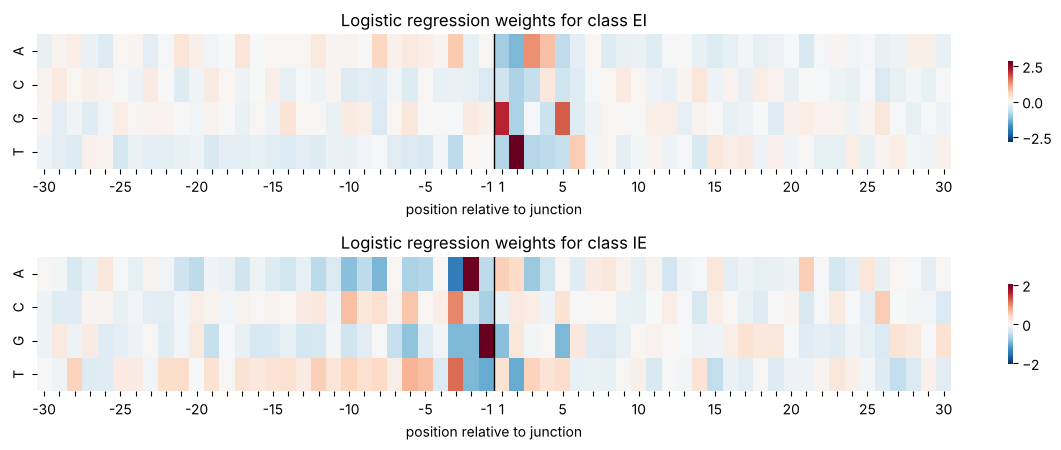

EI → ['+2:T', '+1:G', '+5:G', '+3:A', '+4:A']
IE → ['-1:G', '-2:A', '-3:T', '-3:C', '-6:T']


In [7]:
def weight_heatmap(W, title, ax, vmax=None):
    # W has 240 entries ordered position-major: reshape to (60 positions, 4 bases) then transpose.
    grid = W.reshape(60, 4).T
    vmax = vmax or np.abs(grid).max()
    sns.heatmap(grid, cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax, ax=ax,
                yticklabels=BASES, xticklabels=[str(p) if p % 5 == 0 or abs(p) == 1 else "" for p in POSITIONS],
                cbar_kws={"shrink": 0.6})
    ax.axvline(30, color="black", lw=1)          # the junction sits between index 29 and 30
    ax.set_title(title)
    ax.set_xlabel("position relative to junction")

fig, axes = plt.subplots(2, 1, figsize=(12, 4.6))
for ax, cls in zip(axes, ["EI", "IE"]):
    W = logreg.coef_[list(logreg.classes_).index(cls)]
    weight_heatmap(W, f"Logistic regression weights for class {cls}", ax)
plt.tight_layout()
plt.savefig("../figures/01_logreg_weights.png", dpi=150)
plt.show()

# The five most positive weights per class, by name
for cls in ["EI", "IE"]:
    W = logreg.coef_[list(logreg.classes_).index(cls)]
    top = np.argsort(W)[::-1][:5]
    print(cls, "→", [names[i] for i in top])

## Summary

* A plain logistic regression on one-hot bases gets well above 90% accuracy, and its largest weights
  land exactly on the GT…AG consensus. This indicates that the model has rediscovered the textbook splice signal.
* kNN is slightly weaker. The one-hot vectors of two random sequences are rarely "close".

Logistic regression is the **baseline**. In `02_perceptron_to_mlp.ipynb` we build a single
artificial neuron by hand, show it *is* logistic regression, then add a hidden layer and see
whether a neural network can beat it.